# Lab 04 — Performance measures and comparing classifiers

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Lab 3 ended with a question: the NordicMart tree chosen by accuracy finds 22 of 108 churners — is accuracy the right number
to choose with? Lecture 10b gave the toolbox, Lecture 11 three new classifiers. Today we put both into code, and we end by
teaching `GridSearchCV` to choose with **NordicMart's own money**.

| # | Step | Where |
|---|---|---|
| 1 | Confusion matrix, precision, recall, F1, κ, MCC — the numbers of Lecture 10b | A |
| 2 | Probabilities and thresholds | A |
| 3 | Change `scoring`, change the winner | B |
| 4 | Four classifiers with pipelines: tree, Naïve Bayes, logistic regression, kNN | C |
| 5 | One look at the test set: AUC, log loss, ROC curves | C |
| 6 | **A custom scorer with the churn costs**: cost-sensitive selection, then the threshold | D |
| ★ | The threshold tuned by scikit-learn; a different cost matrix; multi-class averages | E |

- **Part A (≈ 25 min)** — the tree of Lecture 10b, read with all the measures.
- **Part B (≈ 15 min)** — the grid of Lab 3, with six different `scoring`.
- **Part C (≈ 30 min)** — the comparison table of Lecture 11, rebuilt.
- **Part D (≈ 35 min)** — the cost experiment.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (as in Labs 1–3)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**. In Part A we look at it only to *reproduce* the slides of Lecture 10b: no choice is made there.
  From Part B on, every choice is made with cross-validation on the training part; the test set is opened once in C5 and once in D5.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the measures of Lecture 10b (`sklearn.metrics`), the three classifiers of Lecture 11, the pieces of a pipeline,
`DummyClassifier` (the "nobody churns" baseline as a real model), `make_scorer` to build our own scoring, and
`cross_val_predict` (out-of-fold predictions).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict,
                                     TunedThresholdClassifierCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, classification_report,
                             roc_auc_score, roc_curve, log_loss, make_scorer)
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.8.0 | pandas 3.0.1


`TunedThresholdClassifierCV` (used only in ★ E1) needs scikit-learn 1.5 or later. If the import fails, update scikit-learn
or remove it from the import list.

# Part A — Reading a classifier with all the measures

## A1. Data, split, folds

The same preparation as Lab 3, Part C: run the cell, do not change it.

In [2]:
df = pd.read_csv(NORDICMART_FILE)
FEATURES = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]
Xn = df[FEATURES].copy()
Xn["tier"] = Xn["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2})
yn = df["churned"]

Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=SEED)
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print(f"training: {len(yn_train)} customers, {yn_train.sum()} churners | test: {len(yn_test)} customers, {yn_test.sum()} churners")

training: 2100 customers, 252 churners | test: 900 customers, 108 churners


## A2. The confusion matrix

The running tree of Lecture 10b is `DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=0)`: the configuration
that 5-fold CV chooses when the score is AUC (we will check it in Part B).

1. Learn it on the training part; call it `tree_10b`. Predict the test set: `pred_10b`.
1. [`confusion_matrix(y_true, y_pred)`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html):
   print it. Which row is "true churn"? Which column is "predicted churn"?
1. `.ravel()` flattens it into `tn, fp, fn, tp` (in this order, for labels 0 and 1). Print the four numbers.
1. Draw it with `ConfusionMatrixDisplay.from_predictions(..., display_labels=["stay", "churn"])`.

[[764  28]
 [ 82  26]]
TN=764  FP=28  FN=82  TP=26


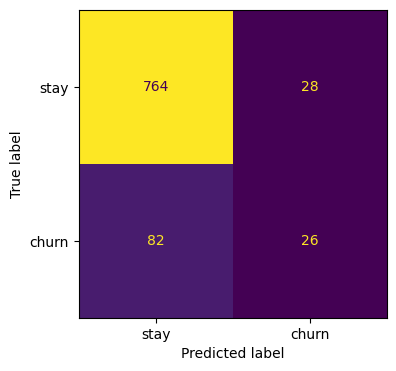

In [3]:
tree_10b = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=0).fit(Xn_train, yn_train)
pred_10b = tree_10b.predict(Xn_test)

cm = confusion_matrix(yn_test, pred_10b)
print(cm)
tn, fp, fn, tp = cm.ravel()      # transforms a matrix into a 1D array and unpacks it into the four variables
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
ConfusionMatrixDisplay.from_predictions(yn_test, pred_10b, display_labels=["stay", "churn"], colorbar=False);

**Answer.** Rows are the truth, columns the prediction, classes in increasing order (0 = stay, 1 = churn). So the **bottom-right**
cell is TP = 26 and the **top-left** TN = 764: the opposite corner from the slides of Lecture 10b, which put the positive class first.
Same numbers: TN = 764, FP = 28, FN = 82, TP = 26. Always check the order before reading a confusion matrix.

## A3. Measures by hand, measures by scikit-learn

1. From `tn, fp, fn, tp` only, compute accuracy, precision, recall, specificity and F1.
1. Compute the same five with scikit-learn (`accuracy_score`, `precision_score`, `recall_score`, `f1_score`; specificity is the
   recall of class 0: `recall_score(..., pos_label=0)`), plus `cohen_kappa_score` and `matthews_corrcoef`.
1. Do the same for the baseline "nobody churns": `DummyClassifier(strategy="most_frequent")`, learned on the training part.
   Its precision is $0/0$: pass `zero_division=0` to `precision_score` and `f1_score` to avoid the warning.

Put both in one DataFrame, one column per model.

In [4]:
by_hand = {"accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": tp / (tp + fp), "recall": tp / (tp + fn),
           "specificity": tn / (tn + fp)}
by_hand["F1"] = 2 * by_hand["precision"] * by_hand["recall"] / (by_hand["precision"] + by_hand["recall"])
print({k: round(v, 3) for k, v in by_hand.items()})

def measures(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "specificity": recall_score(y_true, y_pred, pos_label=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "kappa": cohen_kappa_score(y_true, y_pred),
            "MCC": matthews_corrcoef(y_true, y_pred)}

dummy = DummyClassifier(strategy="most_frequent").fit(Xn_train, yn_train)
pd.DataFrame({"tree 10b": measures(yn_test, pred_10b), "nobody churns": measures(yn_test, dummy.predict(Xn_test))})

{'accuracy': np.float64(0.878), 'precision': np.float64(0.481), 'recall': np.float64(0.241), 'specificity': np.float64(0.965), 'F1': np.float64(0.321)}


,tree 10b,nobody churns
accuracy,0.878,0.88
precision,0.481,0.00
recall,0.241,0.00
specificity,0.965,1.00
F1,0.321,0.00
kappa,0.262,0.00
MCC,0.281,0.00


**Questions.**

1. Which measures say the tree is useful, and which say it is no better than doing nothing?
1. What does a precision of 0.48 mean for the retention team, in one sentence? And a recall of 0.24?

**Answers.**

1. Accuracy says nothing: 0.878 against 0.880 of the baseline. Precision (0.48 vs undefined, reported as 0), recall (0.24 vs 0), F1 (0.32 vs 0),
   κ (0.26 vs 0) and MCC (0.28 vs 0) all show that the tree finds churners and the baseline finds none. Specificity is high for both (0.96 and 1):
   it measures how well we recognize the **majority** class, the easy part.
1. Precision: of the customers the tree flags, about one in two really leaves — four times the 12% of a random pick. Recall: of the customers
   who leave, the tree finds one in four; three out of four leave without being contacted.

## A4. The classification report

`classification_report(y_true, y_pred, target_names=["stay", "churn"], digits=3)` prints all the per-class measures at once.
Print it for the tree.

In [5]:
print(classification_report(yn_test, pred_10b, target_names=["stay", "churn"], digits=3))

              precision    recall  f1-score   support

        stay      0.903     0.965     0.933       792
       churn      0.481     0.241     0.321       108

    accuracy                          0.878       900
   macro avg      0.692     0.603     0.627       900
weighted avg      0.852     0.878     0.859       900



**Questions.**

1. Where are the precision and recall of A3? What is the recall of the row `stay`?
1. Lecture 10b, *Averaging per-class measures*: check that the `macro avg` of F1 is the simple mean of the two F1 values,
   and the `weighted avg` the mean weighted by the `support`. Why is the weighted one so much higher?
1. Where is the *micro* average? (Hint: Lecture 10b, with one label per record.)

**Answers.**

1. Row `churn`: precision 0.481, recall 0.241, F1 0.321. The recall of `stay` (0.965) is the specificity of A3: recall of the negative class.
1. Macro F1 = (0.933 + 0.321)/2 = 0.627; weighted F1 = (0.933·792 + 0.321·108)/900 = 0.859. The weighted average gives 88% of the weight to
   `stay`, the class the tree handles well; the macro average gives the two classes the same weight, so the weak `churn` pulls it down.
   The gap between the two is itself a signal that the minority class is handled badly.
1. With one label per record, micro precision = micro recall = micro F1 = accuracy: it is the `accuracy` row, 0.878.

## A5. Probabilities and the threshold

`predict` uses a threshold of 0.5 on the probability of churn. `predict_proba(X)[:, 1]` gives the probability itself.

1. Compute `p_10b`, the churn probability of the test customers. How many distinct values does it have? Why?
1. Write a function `predict_at(p, t)` returning the crisp prediction `1` when `p >= t`, else `0`.
   Check that `predict_at(p_10b, 0.5)` gives exactly `pred_10b`.
1. Use `measures` of A3 with the threshold 0.15 of the slides, and compare with 0.5.
1. Draw precision, recall and F1 against the threshold, for thresholds from 0.02 to 0.75 (step 0.01), as in the slide
   *Moving the threshold: precision vs recall*.

Reminder: we are reproducing a slide on the test set. We are **not choosing** the threshold here — that is Part D, on training data.

distinct probabilities: 13 | leaves: 13
             t = 0.5  t = 0.15
accuracy       0.878     0.812
precision      0.481     0.322
recall         0.241     0.509
specificity    0.965     0.854
F1             0.321     0.394
kappa          0.262     0.290
MCC            0.281     0.301


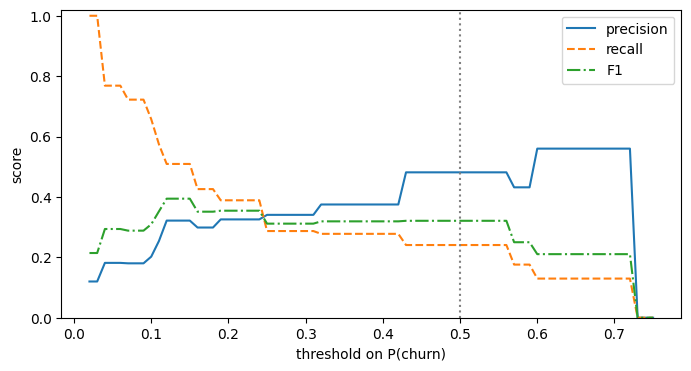

In [6]:
p_10b = tree_10b.predict_proba(Xn_test)[:, 1]
print("distinct probabilities:", len(np.unique(p_10b)), "| leaves:", tree_10b.get_n_leaves())

def predict_at(p, t):
    return (p >= t).astype(int) # astype(int) converts the boolean array to integers (0 and 1)

assert (predict_at(p_10b, 0.5) == pred_10b).all()   # asserting that the predictions at threshold 0.5 
                                                    # are the same as the original predictions
print(pd.DataFrame({"t = 0.5": measures(yn_test, predict_at(p_10b, 0.5)),
                    "t = 0.15": measures(yn_test, predict_at(p_10b, 0.15))}).round(3))

with warnings.catch_warnings():
    warnings.simplefilter("ignore")                                  # precision 0/0 at the highest thresholds
    ts = np.round(np.arange(0.02, 0.76, 0.01), 2)
    curve = pd.DataFrame([measures(yn_test, predict_at(p_10b, t)) for t in ts], index=ts)
ax = curve[["precision", "recall", "F1"]].plot(style=["-", "--", "-."])
ax.axvline(0.5, color="gray", ls=":")
ax.set_xlabel("threshold on P(churn)"); ax.set_ylabel("score"); ax.set_ylim(0, 1.02);

**Answer.** 13 distinct probabilities: one per leaf, because every customer in a leaf gets the fraction of churners of that leaf.
At 0.15 the tree raises many more alarms: recall goes from 0.24 to 0.51, precision falls from 0.48 to 0.32, F1 rises from 0.32 to 0.39,
κ from 0.26 to 0.29 — while accuracy *drops* to 0.82. Lower threshold, more positives: recall up, precision down. The curves are staircases
because there are only 13 probabilities: between two consecutive leaf values nothing changes.

# Part B — Change the measure, change the winner

## B1. Six scorings on the grid of Lab 3

The grid of Lab 3: `max_depth` 2–6, `min_samples_leaf` 1, 10, 30, `criterion` gini/entropy (30 configurations).
In Lab 3 we wrote `scoring="accuracy"`. Now run the same `GridSearchCV` (estimator `DecisionTreeClassifier(random_state=0)`,
folds `cv_n`) with each of

`"accuracy"`, `"precision"`, `"recall"`, `"f1"`, `"roc_auc"`, `"neg_log_loss"`

and collect, for each, the winning configuration and its best mean CV score. (Some folds may give 0/0 precision: silence the warnings
with `warnings.catch_warnings()` as in A5.)

In [7]:
param_grid = {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [1, 10, 30], "criterion": ["gini", "entropy"]}

def show(c):
    return f"{c['criterion']}/d{c['max_depth']}/msl{c['min_samples_leaf']}"

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for s in ["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]:
        g = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid, cv=cv_n, scoring=s).fit(Xn_train, yn_train)
        rows.append({"scoring": s, "winner": show(g.best_params_), "best mean CV score": round(g.best_score_, 4)})
pd.DataFrame(rows)

,scoring,winner,best mean CV score
0,accuracy,entropy/d5/msl10,0.893
1,precision,gini/d3/msl1,0.639
2,recall,gini/d5/msl10,0.314
3,f1,entropy/d6/msl10,0.394
4,roc_auc,gini/d4/msl30,0.757
5,neg_log_loss,entropy/d2/msl1,-0.310


`neg_log_loss` is negative because `GridSearchCV` always **maximizes**: to minimize a loss, scikit-learn maximizes its opposite.

## B2. One search, all the measures

`scoring` also accepts a **list** of measures; then `refit` says which one chooses the final model. Run one search with
the same six measures of B1, `scoring=["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]`, and `refit="roc_auc"`.
In `cv_results_` every measure now has its own columns: `mean_test_accuracy`, `rank_test_recall`, …

For each measure, take the configuration of rank 1 and show **all six** of its mean CV scores: one row per winner, six rows.
Show the log loss with its natural sign (lower is better): change the sign of the `neg_log_loss` column.

In [8]:
MEASURES = ["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # ignore precision 0/0 at the highest thresholds
    multi = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid, cv=cv_n,
                         scoring=MEASURES, refit="roc_auc").fit(Xn_train, yn_train)
r = pd.DataFrame(multi.cv_results_)
winners = pd.DataFrame({f"best on {m}": r.loc[r[f"rank_test_{m}"].idxmin(),\
                                               [f"mean_test_{k}" for k in MEASURES]].values
                        for m in MEASURES}, index=MEASURES).T.astype(float)
winners["neg_log_loss"] = -winners["neg_log_loss"]
winners = winners.rename(columns={"neg_log_loss": "log loss"}).rename(index={"best on neg_log_loss": "best on log loss"})
winners.insert(0, "configuration", [show(r.loc[r[f"rank_test_{m}"].idxmin(), "params"]) for m in MEASURES])
print("refit on roc_auc:", show(multi.best_params_))
winners

refit on roc_auc: gini/d4/msl30


,configuration,accuracy,precision,recall,f1,roc_auc,log loss
best on accuracy,entropy/d5/msl10,0.893,0.638,0.282,0.386,0.727,0.673
best on precision,gini/d3/msl1,0.888,0.639,0.231,0.322,0.723,0.378
best on recall,gini/d5/msl10,0.882,0.519,0.314,0.389,0.738,0.548
best on f1,entropy/d6/msl10,0.893,0.622,0.294,0.394,0.721,0.849
best on roc_auc,gini/d4/msl30,0.888,0.591,0.239,0.333,0.757,0.318
best on log loss,entropy/d2/msl1,0.889,0.613,0.254,0.348,0.743,0.310


**Questions.**

1. How many different winners do the six scorings produce? Which one gives the tree of Lecture 10b?
1. Read the table of B2 by columns. Is there a configuration that is best on every measure? Look in particular at the log-loss column
   (the constant guess 0.12 for everybody has log loss about 0.37).
1. The accuracy winner has precision 0.64 and recall 0.28. If the retention team said "we want to find many churners, false alarms are cheap",
   which row would you pick? And which `scoring`?

**Answers.**

1. Six scorings, **six different winners**: accuracy `entropy`/d5/msl10 (the winner of Lab 3, C4), precision `gini`/d3/msl1, recall `gini`/d5/msl10,
   F1 `entropy`/d6/msl10, AUC `gini`/d4/msl30 — the tree of Lecture 10b — and log loss `entropy`/d2/msl1. The choice of the measure is part of model selection.
1. No. Each winner is best on its own column and worse on the others: the precision winner has the lowest recall (0.23), the recall winner the
   lowest precision (0.52) and the lowest accuracy (0.882), the AUC winner has the second-lowest recall (0.24). Each measure answers a different question.
   The log-loss column is the most striking: the accuracy, recall and F1 winners (depth 5–6, small leaves) have log loss 0.55–0.85, **worse than the
   constant guess 0.12 for everybody (about 0.37)**: their small leaves give extreme probabilities, 0 or 1, and confident mistakes are punished hard.
   The AUC winner (leaves of at least 30 customers) and the log-loss winner (depth 2) stay near 0.31.
1. The recall winner (`gini`/d5/msl10: recall 0.31), with `scoring="recall"` — or better, since false alarms are not *free*, a measure
   that weighs the two errors by what they cost. With the actual numbers of the business: Part D.

# Part C — Four classifiers on NordicMart

## C1. The preparation of Lecture 11

Naïve Bayes, logistic regression and kNN need complete, numeric, comparable attributes. Lecture 11, *Naïve Bayes on NordicMart:
reading the results*, listed the preparation. Write a function `prepare(X)` that takes the raw columns (`Xn`) and returns a **new** DataFrame with:

| new column | from |
|---|---|
| `tier` | `tier` (already 0/1/2) |
| `age` | `age`, with 0 (default value at the till) → `NaN` |
| `recency` | `days_since_last_buy`, with 999 ("never bought") → `NaN` |
| `never_bought` | 1 if `days_since_last_buy == 999`, else 0 |
| `log_spend` | `log10(annual_spend)` |
| `sessions` | `web_sessions_month`, with `NaN` (store-only customer) → 0 |
| `store_only` | 1 if `web_sessions_month` is missing, else 0 |
| `tickets` | `tickets_90d` |

These are **fixed rules** from the EDA log: nothing is computed from the data, so they can be applied to training and test alike.
Apply it: `Xp_train = prepare(Xn_train)`, `Xp_test = prepare(Xn_test)`. How many missing values are left, and in which columns?

In [9]:
def prepare(X):
    return pd.DataFrame({
        "tier": X["tier"],
        "age": X["age"].replace(0, np.nan),
        "recency": X["days_since_last_buy"].replace(999, np.nan),
        "never_bought": (X["days_since_last_buy"] == 999).astype(int), # this is a new feature that indicates whether the customer has never bought anything
        "log_spend": np.log10(X["annual_spend"]), # this is a new feature that takes the logarithm of the annual spend to reduce skewness
        "sessions": X["web_sessions_month"].fillna(0), #
        "store_only": X["web_sessions_month"].isna().astype(int), # this is a new feature that indicates whether the customer has only shopped in-store and never online
        "tickets": X["tickets_90d"]},
        index=X.index # this ensures that the index of the new DataFrame matches the original DataFrame, which is important for aligning the features with the target variable
        )

Xp_train, Xp_test = prepare(Xn_train), prepare(Xn_test)
Xp_train.isna().sum()[lambda s: s > 0] # remaining missing values in the training set after feature engineering

age        237
recency     37
dtype: int64

**Answer.** Only `age` and `recency` still have missing values (the true unknowns and the default ages, and the never-buyers' recency).
They will be filled with the **median** — but the median is computed from data, so it must be learned on the training folds of each CV round: inside the pipeline.

## C2. Pipelines and four searches

Lecture 11, *Standardization*: `make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)` is **one estimator**:
`fit` learns medians, means and standard deviations on the data it receives, then the model; `GridSearchCV` refits the whole chain in every round,
so the held-out fold never contributes to the preparation.

The hyperparameters of a step are named `<step name>__<parameter>`, where the step name is the class name in lower case
(e.g. `logisticregression__C`). Prepare a dictionary `candidates = {name: (estimator, grid, X_train)}`:

| name | estimator | grid | data |
|---|---|---|---|
| `tree` | `DecisionTreeClassifier(random_state=0)` | `max_depth` 2–6, `min_samples_leaf` 1, 10, 30 | raw: `Xn_train` |
| `naive Bayes` | pipeline + `GaussianNB()` | none: `{}` | `Xp_train` |
| `logistic regression` | pipeline + `LogisticRegression(max_iter=2000)` | `C` in 0.001, 0.01, 0.1, 1, 10, 100 | `Xp_train` |
| `kNN` | pipeline + `KNeighborsClassifier()` | `n_neighbors` in 1, 5, 15, 31, 51, 101, 201, 301, 401 | `Xp_train` |

For each: `GridSearchCV(estimator, grid, cv=cv_n, scoring="roc_auc")`, `fit`, and store the fitted search in a dictionary `searches`.
Then a table with best parameters, mean and standard deviation of the CV AUC of the winner.

### Note
The tree keeps the raw columns, as in Lecture 10: it handles missing values and scales by itself:
1. In the most recent implementation of DecisionTreeClassifier, the missing values are automatically considered, as shown in https://scikit-learn.org/stable/modules/tree.html#missing-values-supports, therefore it is not necessary to do imputation with SimpleImputer 
2. Decision trees are not influenced by the distributions of values in a feature, therefore the Standard Scaler is not necessary

In [10]:
def pipe(model):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

candidates = {
    "tree": (DecisionTreeClassifier(random_state=0), {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [1, 10, 30]}, Xn_train),
    "naive Bayes": (pipe(GaussianNB()), {}, Xp_train),
    "logistic regression": (pipe(LogisticRegression(max_iter=2000)),
                            {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}, Xp_train),
    "kNN": (pipe(KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [1, 5, 15, 31, 51, 101, 201, 301, 401]}, Xp_train)}

searches, rows = {}, []
for name, (est, grid, X_tr) in candidates.items():
    s = GridSearchCV(est, grid, cv=cv_n, scoring="roc_auc").fit(X_tr, yn_train)
    searches[name] = s
    i = s.best_index_
    rows.append({"model": name, "best params": s.best_params_,
                 "CV AUC": s.cv_results_["mean_test_score"][i], "std": s.cv_results_["std_test_score"][i]})
cv_table = pd.DataFrame(rows).set_index("model")
cv_table

,best params,CV AUC,std
model,,,
tree,"{'max_depth': 4, 'min_samples_leaf': 30}",0.757,0.030
naive Bayes,{},0.788,0.041
logistic regression,{'logisticregression__C': 0.1},0.823,0.035
kNN,{'kneighborsclassifier__n_neighbors': 401},0.819,0.032


**Questions.**

1. Which model would you choose, looking **only** at this table? Is its advantage over the second larger than the noise?
1. GaussianNB has an empty grid. What does `GridSearchCV` do then?

**Answers.**

1. Logistic regression (0.823 ± 0.035) and kNN with k = 401 (0.819 ± 0.032): 0.004 apart, a tenth of a standard deviation — equivalent within the
   noise. As in Lecture 11, prefer logistic regression: simpler, faster to predict, interpretable weights. Naïve Bayes (0.788) and the tree (0.757,
   the tree of Lecture 10b again) are behind, though Naïve Bayes only by one standard deviation.
1. One configuration only: it computes its 5-fold CV score and refits it on the whole training part. It is the same as `cross_val_score` + `fit`,
   with the advantage that all four models are handled in the same way.

## C3. One look at the test set

The choice was made in C2. Now, **once**, measure the four refitted winners (`searches[name].best_estimator_`, or simply `searches[name]`)
on the test set — the tree on `Xn_test`, the others on `Xp_test` — and reproduce the table of Lecture 11, *Four classifiers on NordicMart*:

- test AUC and log loss (probabilities);
- precision, recall and κ at the default threshold 0.5;
- the total cost at the threshold **0.15** of the slides (fixed in Lecture 10b, not chosen here): € 10 for every false positive, € 100 for every false negative.

Add the constant model that predicts the churn rate of the training part (0.12) for everybody: AUC 0.5, and its log loss.
Store the test probabilities in a dictionary `p_test`: we will need them for the ROC curves.

In [ ]:
X_test_of = {"tree": Xn_test}                               # every other model takes the prepared columns
p_test, rows = {}, []
for name, s in searches.items():
    p = s.predict_proba(X_test_of.get(name, Xp_test))[:, 1] # .get(name, Xp_test) returns Xn_test for the tree model 
                                                            # and Xp_test (the default value in the get argument) 
                                                            # for all other models
    p_test[name] = p
    yp = predict_at(p, 0.5)
    tn_, fp_, fn_, tp_ = confusion_matrix(yn_test, predict_at(p, 0.15)).ravel()
    rows.append({"model": name, "test AUC": roc_auc_score(yn_test, p), "log loss": log_loss(yn_test, p),
                 "precision 0.5": precision_score(yn_test, yp, zero_division=0), "recall 0.5": recall_score(yn_test, yp),
                 "kappa 0.5": cohen_kappa_score(yn_test, yp), "cost 0.15 (EUR)": 10 * fp_ + 100 * fn_})
const = np.full(len(yn_test), yn_train.mean())
rows.append({"model": "constant 0.12", "test AUC": 0.5, "log loss": log_loss(yn_test, const)})
test_table = pd.DataFrame(rows).set_index("model")
cv_table[["CV AUC", "std"]].join(test_table, how="right")

,CV AUC,std,test AUC,log loss,precision 0.5,recall 0.5,kappa 0.5,cost 0.15 (EUR)
model,,,,,,,,
tree,0.757,0.030,0.713,0.339,0.481,0.241,0.262,6460.0
naive Bayes,0.788,0.041,0.761,0.518,0.380,0.426,0.315,6180.0
logistic regression,0.823,0.035,0.788,0.305,0.525,0.194,0.234,5800.0
kNN,0.819,0.032,0.768,0.321,0.000,0.000,0.000,6530.0
constant 0.12,NaN,NaN,0.500,0.367,NaN,NaN,NaN,NaN


**Questions.**

1. Does the test confirm the choice made on CV? Why is each test AUC a little lower than the CV AUC?
1. Which model has the best ranking, which the best probabilities? Which is worse than the constant guess on log loss, and why?
1. kNN has κ = 0 and recall 0 at 0.5, yet the second-best test AUC. Explain.

**Answers.**

1. Yes: logistic regression is first on the test set too (AUC 0.788), then kNN (0.768), Naïve Bayes (0.761), the tree (0.713). The CV AUC of the winner
   is the best of several configurations, so it carries a little of the winner's curse of Lab 3; and 900 customers give a noisy estimate: the
   differences are within the uncertainty.
1. Logistic regression is best on both: ranking (AUC) and probabilities (log loss 0.305, below the 0.37 of the constant guess). Naïve Bayes has a
   good ranking but log loss 0.52, **worse than the constant**: correlated attributes (`store_only` and `sessions`, `never_bought` and `recency`)
   count the same evidence twice and push its probabilities towards 0 and 1 — confident mistakes are what log loss punishes most.
1. With 401 neighbours, a customer needs more than 200 churners among them to get a probability above 0.5: it never happens, so no alarm, recall 0, κ 0.
   The *ranking* is good (AUC 0.77): lower the threshold and the alarms appear (at 0.15: cost € 6 530, far below the € 10 800 of no alarm at all).
   κ, precision and recall judge one threshold; AUC judges the ranking.

## C4. ROC curves

Draw on one figure the four ROC curves on the test set (`roc_curve(yn_test, p)` returns false positive rate, true positive rate and thresholds),
with the AUC in the legend and the diagonal of the random classifier.

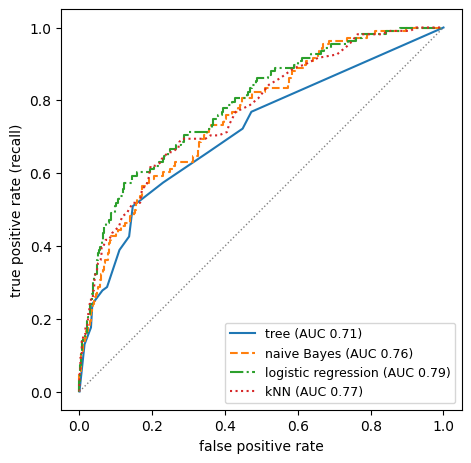

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5.2))
for (name, p), ls in zip(p_test.items(), ["-", "--", "-.", ":"]):
    fpr, tpr, _ = roc_curve(yn_test, p)
    ax.plot(fpr, tpr, ls=ls, label=f"{name} (AUC {roc_auc_score(yn_test, p):.2f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1, ls=":") # this is the diagonal line representing random guessing
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate (recall)"); ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=9);

**Question.** The tree's curve is made of a few straight segments, the others are much finer. Why? Do the curves cross?

**Answer.** The tree gives only 13 distinct probabilities (one per leaf): 13 thresholds, 13 corners joined by straight lines. Logistic regression and
Naïve Bayes give a different probability to almost every customer; kNN with k = 401 gives one of at most 402 values. The curves cross: logistic regression
and kNN swap places several times (kNN is above at false positive rates of 2% and 20%, below at 5% and 10%), and at the far left even Naïve Bayes is above logistic
regression. AUC summarizes the whole curve, but at one particular operating point the order of two models can be different. That is why, once the business fixes the operating point, we should choose with the **cost** at that point: Part D.

# Part D — A custom scorer with the churn costs

Lecture 10b, *NordicMart: a cost matrix*: a flagged customer receives an offer that costs **€ 10**; a churner who is not flagged is lost,
with **€ 100** of margin. Assumption: the offer keeps the churners it reaches.

| | predicted stay | predicted churn |
|---|---|---|
| **true stay** | 0 | € 10 (FP) |
| **true churn** | € 100 (FN) | 0 (TP) |

Every measure of Part B was a **proxy** for this table. Now we give the table itself to `GridSearchCV`.

## D1. The cost function

1. Write `churn_cost(y_true, y_pred)` returning the total cost in euros. Use `confusion_matrix(..., labels=[0, 1])`, so that it works
   even when a fold contains predictions of one class only.
1. The CV folds have 420 customers, the test set 900: to compare them, write also `cost_per_customer(y_true, y_pred)`, the average cost
   in euros per customer.
1. Check on the slide: the tree of Lecture 10b at threshold 0.5 on the test set costs € 8 480; "nobody gets the offer" € 10 800;
   "everybody gets it" € 7 920. Print also the three costs per customer.

In [13]:
COST_FP, COST_FN = 10, 100

def churn_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return COST_FP * fp + COST_FN * fn

def cost_per_customer(y_true, y_pred):
    return churn_cost(y_true, y_pred) / len(y_true)

for name, yp in [("tree 10b, t = 0.5", pred_10b), ("nobody", np.zeros(len(yn_test), int)), ("everybody", np.ones(len(yn_test), int))]:
    print(f"{name:18s} EUR {churn_cost(yn_test, yp):6,d}   {cost_per_customer(yn_test, yp):5.2f} per customer")

tree 10b, t = 0.5  EUR  8,480    9.42 per customer
nobody             EUR 10,800   12.00 per customer
everybody          EUR  7,920    8.80 per customer


## D2. `make_scorer`: choosing the tree by cost

[`make_scorer`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html) turns a function
`f(y_true, y_pred)` into a `scoring` object. `GridSearchCV` maximizes, and a cost must be minimized: say so with
`greater_is_better=False` (scikit-learn will report the cost with a minus sign).

1. `cost_scorer = make_scorer(cost_per_customer, greater_is_better=False)`.
1. Run the tree grid of Part B (`param_grid`, 30 configurations) with `scoring=cost_scorer`. Winner, and its CV cost per customer
   (remember the sign)? Compare with the two trivial strategies on the training part: 100 · (churn rate) per customer for "nobody",
   10 · (1 − churn rate) for "everybody".
1. **Cost-sensitive learning** (Lecture 10b): add `class_weight` to the grid, with values `None`, `"balanced"` and `{0: 1, 1: 10}`
   (a churner counts as ten customers in the impurity). Run it again. Winner, cost, and the best cost reached by each value of `class_weight`.

In [14]:
cost_scorer = make_scorer(cost_per_customer, greater_is_better=False)

cost_search = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid, cv=cv_n, scoring=cost_scorer).fit(Xn_train, yn_train)
rate = yn_train.mean()
print(f"winner {show(cost_search.best_params_)}: EUR {-cost_search.best_score_:.2f} per customer"
      f" | nobody {COST_FN * rate:.2f} | everybody {COST_FP * (1 - rate):.2f}")

grid_cw = {**param_grid, "class_weight": [None, "balanced", {0: 1, 1: 10}]}
cw_search = GridSearchCV(DecisionTreeClassifier(random_state=0), grid_cw, cv=cv_n, scoring=cost_scorer).fit(Xn_train, yn_train)
print(f"with class_weight: {show(cw_search.best_params_)}, class_weight={cw_search.best_params_['class_weight']}:"
      f" EUR {-cw_search.best_score_:.2f} per customer")

r = pd.DataFrame(cw_search.cv_results_)
r["class_weight"] = r["params"].map(lambda p: str(p["class_weight"]))      # None stays visible as "None"
(-r.groupby("class_weight")["mean_test_score"].max()).rename("best CV cost per customer")

winner gini/d5/msl10: EUR 8.59 per customer | nobody 12.00 | everybody 8.80
with class_weight: entropy/d5/msl30, class_weight={0: 1, 1: 10}: EUR 5.96 per customer


class_weight
None             8.590
balanced         6.319
{0: 1, 1: 10}    5.957
Name: best CV cost per customer, dtype: float64

**Questions.**

1. Without `class_weight`, does choosing by cost help much? Why can no tree, at threshold 0.5, get close to the cost of the slide at 0.15?
1. With `class_weight={0: 1, 1: 10}` the cost falls a lot. What does the weight do to the leaves of the tree? Relate the factor 10 to the cost matrix.

**Answers.**

1. Very little: the best unweighted tree costs about € 8.6 per customer in CV, better than "nobody" (12.0) and only slightly better than
   "everybody" (8.8). Choosing the configuration does not move the decision rule: at 0.5, a leaf predicts churn only if **most** of its customers churn,
   and with 12% churners such leaves are few. Every tree stays too cautious, and a missed churner costs ten times a wasted offer.
1. € 5.96 per customer (`entropy`, depth 5, leaf ≥ 30, weights 1:10), against € 8.59 without weights. With weight 10 a leaf predicts churn as soon as 10 × (churners) > (stayers), i.e. when more than 1/11 ≈ 9% of its customers churn:
   the weight moves the threshold of every leaf from 0.5 to 10/110 — exactly the cost ratio $c_{FP}/(c_{FP}+c_{FN})$ of Lecture 10b. It also changes
   *how the tree is grown*: the splits are chosen to isolate churners. `"balanced"` gives a weight of about 7.3 (= 88/12), close to 10: almost as good (€ 6.32).

## D3. A scorer that looks at the probabilities

`class_weight` works for the tree, but the other route of Lecture 10b is to keep the model and **move the threshold**. `make_scorer`
receives crisp predictions, made at 0.5. We need a scorer that reads the probabilities and applies our threshold.

A scorer can also be a plain function **`scorer(estimator, X, y)`** returning a number to maximize. Write

```python
def cost_scorer_at_t(estimator, X, y):
    ...   # probabilities of `estimator` on X, prediction at THRESHOLD, minus the cost per customer
```

with `THRESHOLD = COST_FP / (COST_FP + COST_FN)` (= 0.09: the cost-optimal threshold of Lecture 10b *if the probabilities are correct*).
It is fixed by the cost matrix, before looking at any data.

Then run the four searches of C2 again, with the same grids, but `scoring={"cost": cost_scorer_at_t, "auc": "roc_auc"}` and `refit="cost"`
(two measures, the cost chooses). Store them in `cost_searches`. Table: winner, CV cost per customer ± std, CV AUC of the same configuration.

In [15]:
THRESHOLD = COST_FP / (COST_FP + COST_FN)

def cost_scorer_at_t(estimator, X, y):
    return -cost_per_customer(y, predict_at(estimator.predict_proba(X)[:, 1], THRESHOLD))

cost_searches, rows = {}, []
for name, (est, grid, X_tr) in candidates.items():
    s = GridSearchCV(est, grid, cv=cv_n, scoring={"cost": cost_scorer_at_t, "auc": "roc_auc"}, refit="cost").fit(X_tr, yn_train)
    cost_searches[name] = s
    i = s.best_index_
    rows.append({"model": name, "best params": s.best_params_, "CV cost/customer": -s.cv_results_["mean_test_cost"][i],
                 "std": s.cv_results_["std_test_cost"][i], "CV AUC": s.cv_results_["mean_test_auc"][i]})
print(f"threshold {THRESHOLD:.3f}")
pd.DataFrame(rows).set_index("model")

threshold 0.091


,best params,CV cost/customer,std,CV AUC
model,,,,
tree,"{'max_depth': 4, 'min_samples_leaf': 30}",6.086,0.540,0.757
naive Bayes,{},5.962,0.864,0.788
logistic regression,{'logisticregression__C': 10},5.329,0.793,0.823
kNN,{'kneighborsclassifier__n_neighbors': 401},5.467,0.741,0.819


**Questions.**

1. Rank the four models by CV cost. Is it the same ranking as by AUC in C2? Did any winning hyperparameter change?
1. The tree without weights at 0.09 (€ 6.09) costs about the same as the weighted tree of D2 at 0.5 (€ 5.96). Coincidence?
1. Logistic regression and kNN are again close. How many euros per customer separate them, compared with the standard deviation?

**Answers.**

1. Logistic regression € 5.33, kNN € 5.47, Naïve Bayes € 5.96, tree € 6.09 per customer: the same order as AUC. At this threshold the cost agrees with
   the ranking measure — not always true, since the cost judges one operating point and AUC all of them. Logistic regression now chooses C = 10 instead of
   0.1; the tree and kNN keep the AUC winners (depth 4/leaf 30, k = 401).
1. Not a coincidence: the two routes do the same thing in two places. `class_weight={0: 1, 1: 10}` puts the threshold 1/11 inside the training
   (and reshapes the tree); the scorer puts it at prediction time. Both turn the cost matrix into the decision rule.
1. About € 0.14 per customer, against a standard deviation of about € 0.75 across the folds: equivalent within the noise. Logistic regression stays
   our choice for the reasons of C2. Compared with "everybody gets the offer" (€ 8.80) it saves about € 3.5 per customer: for NordicMart's
   240 000 active cardholders, the order of € 800 000 a year — if the assumptions of the cost matrix hold.

## D4. The threshold, chosen on training data

0.09 is optimal only if the probabilities are exactly right. Lecture 10b: *choose the threshold on training or validation data, not on the test set*.
We need probabilities for the training customers that were **not** produced by a model that saw them:
[`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html)
with `method="predict_proba"` returns, for each training customer, the probability given by the model of the round in which that customer was held out
(**out-of-fold** probabilities).

1. Take the cost winner of D3 for logistic regression, `final_lr = cost_searches["logistic regression"].best_estimator_`.
1. Compute its out-of-fold probabilities on the training part (`cv=cv_n`): `p_oof`.
1. For thresholds from 0.02 to 0.60 (step 0.01) compute the cost per customer on the training part; plot it, with horizontal lines for
   "nobody" and "everybody". Which threshold is best (`best_t`)? Compare with 0.09 and 0.5.

best threshold 0.13: EUR 5.20 | at 0.09: 5.33 | at 0.5: 9.56


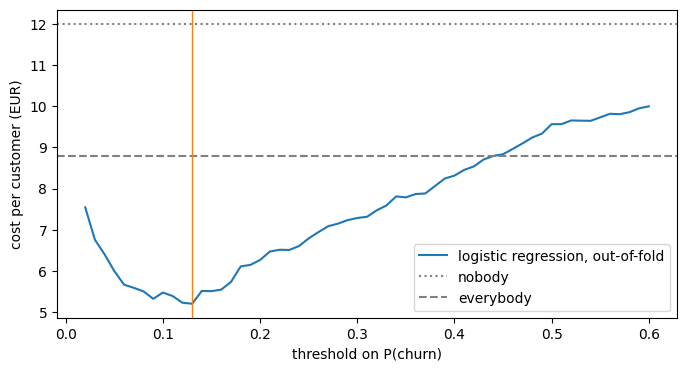

In [16]:
final_lr = cost_searches["logistic regression"].best_estimator_
p_oof = cross_val_predict(final_lr, Xp_train, yn_train, cv=cv_n, method="predict_proba")[:, 1]

ts = np.round(np.arange(0.02, 0.61, 0.01), 2)
oof_cost = pd.Series([cost_per_customer(yn_train, predict_at(p_oof, t)) for t in ts], index=ts)
best_t = oof_cost.idxmin()
print(f"best threshold {best_t:.2f}: EUR {oof_cost.min():.2f} | at {THRESHOLD:.2f}: "
      f"{cost_per_customer(yn_train, predict_at(p_oof, THRESHOLD)):.2f} | at 0.5: {oof_cost[0.5]:.2f}")

ax = oof_cost.plot(label="logistic regression, out-of-fold")
ax.axhline(COST_FN * rate, color="gray", ls=":", label="nobody")
ax.axhline(COST_FP * (1 - rate), color="gray", ls="--", label="everybody")
ax.axvline(best_t, color="C1", lw=1)
ax.set_xlabel("threshold on P(churn)"); ax.set_ylabel("cost per customer (EUR)"); ax.legend();

**Question.** Is the best threshold close to the theoretical 0.09? How sharp is the minimum: how much would we lose with any threshold between 0.07 and 0.17?

**Answer.** The best out-of-fold threshold is 0.13 (€ 5.20 per customer), near the theoretical 0.09 (€ 5.33): logistic regression's probabilities are well
calibrated (Lecture 11), so the theory works well. The valley is **flat and jagged**: between 0.07 and 0.17 the cost stays within about € 0.5 of the minimum and goes
up and down from one step to the next (0.09: 5.33, 0.10: 5.48, 0.12: 5.23), while at 0.5 it almost doubles (€ 9.56). The important decision is "well below 0.5";
the exact value matters much less, and on 2100 customers its second decimal is noise.

## D5. One look at the test set

The decision is now complete and written down **before** opening the test set: logistic regression with the C chosen by CV cost (D3), threshold `best_t` chosen
on out-of-fold probabilities (D4). `final_lr` was already refitted on all 2100 training customers by `GridSearchCV`.

1. Cost on the test set (total and per customer), its confusion matrix, precision and recall.
1. Compare with: "nobody", "everybody", the tree of Lecture 10b at 0.5 (€ 8 480), and logistic regression at the slide's 0.15 (C3).

In [17]:
p_final = final_lr.predict_proba(Xp_test)[:, 1]
pred_final = predict_at(p_final, best_t)
print(confusion_matrix(yn_test, pred_final))
print(f"precision {precision_score(yn_test, pred_final):.3f} | recall {recall_score(yn_test, pred_final):.3f}")

pd.DataFrame({"total cost (EUR)": {
    "nobody gets the offer": churn_cost(yn_test, np.zeros(len(yn_test), int)),
    "everybody gets the offer": churn_cost(yn_test, np.ones(len(yn_test), int)),
    "tree 10b, t = 0.5": churn_cost(yn_test, pred_10b),
    "logistic regression (C3), t = 0.15": test_table.loc["logistic regression", "cost 0.15 (EUR)"],
    f"final: LR, cost-chosen, t = {best_t:.2f}": churn_cost(yn_test, pred_final)}}).assign(
    **{"per customer": lambda d: d["total cost (EUR)"] / len(yn_test)})

[[610 182]
 [ 38  70]]
precision 0.278 | recall 0.648


,total cost (EUR),per customer
nobody gets the offer,10800.0,12.000
everybody gets the offer,7920.0,8.800
"tree 10b, t = 0.5",8480.0,9.422
"logistic regression (C3), t = 0.15",5800.0,6.444
"final: LR, cost-chosen, t = 0.13",5620.0,6.244


**Questions.**

1. How many churners does the final model find, and how many offers does it send? Compare with the tree of Lab 3 (22 churners found, 14 false alarms).
1. The test cost per customer is higher than the CV estimate of D4. Is this worrying?
1. Lecture 10b, wrap-up: "costs decide: measure, threshold, operating point". Summarize in two sentences what the cost matrix changed in this lab.

**Answers.**

1. It flags 252 customers and finds **70 of the 108 churners** (recall 0.65), with 182 offers to customers who would have stayed (precision 0.28).
   The Lab 3 tree found 22 with 14 false alarms: much more "precise", but it let 86 churners go, at € 100 each. Total: € 5 620 against € 8 740 for the Lab 3 tree
   (14 × 10 + 86 × 100) and € 7 920 for contacting everybody.
1. No: € 6.24 on test against € 5.20 out-of-fold. Part of the gap is the optimism of having chosen C and the threshold on those same out-of-fold numbers (the winner's
   curse, again); part is the noise of 900 customers — 10 churners more or less missed are € 1 000, more than € 1 per customer. The ranking of the strategies is
   what matters, and it holds.
1. Accuracy, F1 or AUC chose models that answer *"how good is the classifier?"*; the cost matrix answers *"how much does NordicMart save?"*, and it chose both the
   model and, above all, the threshold — from 0.5 to about 0.1. With the same logistic regression, the threshold alone moves the test cost from
   € 8 690 (at 0.5) to € 5 620.

# Part E — Optional exercises ★

## E1. scikit-learn tunes the threshold ★

D4 is common enough that scikit-learn (≥ 1.5) has a meta-estimator for it:
[`TunedThresholdClassifierCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html).
It wraps a classifier, computes out-of-fold probabilities, chooses the threshold that maximizes `scoring`, and refits.

Wrap `final_lr` with `scoring=cost_scorer` (the crisp scorer of D2: the wrapper applies each candidate threshold before calling it) and `cv=cv_n`;
`fit` it on the training part. Print `best_threshold_`, `-best_score_` and the cost on the test set. Compare with D4–D5.

In [18]:
tuned = TunedThresholdClassifierCV(final_lr, scoring=cost_scorer, cv=cv_n).fit(Xp_train, yn_train)
print(f"threshold {tuned.best_threshold_:.3f} | CV cost per customer {-tuned.best_score_:.2f}"
      f" | test cost EUR {churn_cost(yn_test, tuned.predict(Xp_test)):,d}")

threshold 0.121 | CV cost per customer 5.23 | test cost EUR 5,580


**Answer.** Threshold 0.121 (D4: 0.13), CV cost € 5.23 per customer (D4: 5.20), test cost € 5 580 (D5: € 5 620, four false alarms of difference).
Same procedure, small differences in the details: the wrapper tries 100 thresholds spread over the range of the probabilities instead of our steps of 0.01, and it
averages the cost over the five held-out folds instead of computing it on the pooled out-of-fold probabilities. In such a flat valley these details move the
threshold by a hundredth — noise, as D4 showed.

## E2. A more honest cost matrix ★

The cost matrix of the slides is generous: the offer is free when it reaches a churner, and it always keeps them. Suppose instead that
the offer costs € 10 **to everybody who receives it**, and keeps only **40%** of the churners it reaches. Then a true positive costs
10 + 0.6 · 100 = € 70.

1. Write `churn_cost_2(y_true, y_pred)` with the new matrix (TP € 70, FP € 10, FN € 100, TN 0).
1. Derive the theoretical threshold: flag a customer with churn probability $p$ when the expected cost of flagging, $70p + 10(1-p)$,
   is lower than the expected cost of not flagging, $100p$.
1. With `p_oof` of D4: cost curve per customer, best threshold, and the costs of "nobody" and "everybody". Is the campaign still worth it?

theoretical threshold: 0.25
best 0.24: EUR 10.84 per customer | nobody 12.00 | everybody 17.20


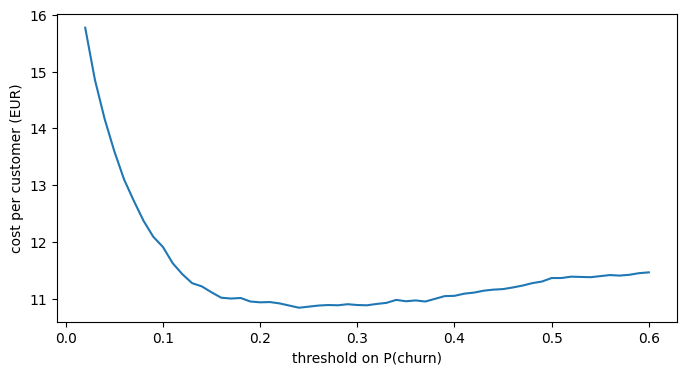

In [19]:
def churn_cost_2(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return 70 * tp + 10 * fp + 100 * fn

print("theoretical threshold:", 10 / (10 + 100 - 70))
cost2 = pd.Series([churn_cost_2(yn_train, predict_at(p_oof, t)) / len(yn_train) for t in ts], index=ts)
n = len(yn_train)
print(f"best {cost2.idxmin():.2f}: EUR {cost2.min():.2f} per customer | nobody {churn_cost_2(yn_train, np.zeros(n, int)) / n:.2f}"
      f" | everybody {churn_cost_2(yn_train, np.ones(n, int)) / n:.2f}")
ax = cost2.plot(); ax.set_xlabel("threshold on P(churn)"); ax.set_ylabel("cost per customer (EUR)");

**Answer.** Flag when $70p + 10 - 10p < 100p$, i.e. $p > 10/40 = 0.25$; the out-of-fold curve agrees (best 0.24, € 10.84 per customer). "Nobody" costs € 12.00,
"everybody" € 17.20: contacting everybody is now much *worse* than doing nothing, and the targeted campaign saves only € 1.2 per customer instead of € 3.5.
The threshold, and even the value of the whole project, depend on two numbers — the price of the offer and the retention rate — that come from the business,
not from the data. The Director of Loyalty's question (NordicMart pack 1) was exactly this: *does the revenue we keep exceed what we spend?*

## E3. Three classes: the averages on Iris ★

Rebuild the Iris data of Lab 3, Part A (50-50 split, `random_state=10`, flowers 113 and 125 altered), learn
`DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)` on the altered training set and print the confusion matrix and the
classification report on the test set (`target_names=iris.target_names`). Which class has the lowest precision, which the lowest recall?
Why are macro and weighted averages so close here, unlike NordicMart?

In [20]:
iris = load_iris(as_frame=True)
Xi = iris.data.copy(); Xi.columns = [c[:-5] for c in Xi.columns]; yi = iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, train_size=0.5, random_state=10)
Xi_alt, yi_alt = Xi_train.copy(), yi_train.copy()
yi_alt.loc[125] = 0; Xi_alt.loc[113] = Xi_alt.loc[125]; yi_alt.loc[113] = 1

tree_iris = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10).fit(Xi_alt, yi_alt)
pred_iris = tree_iris.predict(Xi_test)
print(confusion_matrix(yi_test, pred_iris))
print(classification_report(yi_test, pred_iris, target_names=iris.target_names, digits=3))

[[23  0  0]
 [ 0 22  5]
 [ 0  1 24]]
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        23
  versicolor      0.957     0.815     0.880        27
   virginica      0.828     0.960     0.889        25

    accuracy                          0.920        75
   macro avg      0.928     0.925     0.923        75
weighted avg      0.927     0.920     0.920        75



**Answer.** The 6 errors of Lab 3 are 5 versicolor predicted as virginica and 1 virginica predicted as versicolor. So virginica has the lowest **precision**
(24/29 = 0.83: five of its predictions are versicolor) and versicolor the lowest **recall** (22/27 = 0.81). Setosa is perfect. Macro (F1 0.923) and weighted (0.920)
are almost equal because the three classes have almost the same size (23, 27, 25): weights by size ≈ equal weights. With imbalanced classes — NordicMart,
792 vs 108 — the two averages separate (A4).

## Experiment log

Complete the log (double-click to edit). Costs on the test set are in euros, for the 900 test customers.

| Model | Chosen by | Threshold | CV | Test AUC | Test cost |
|---|---|---|---|---|---|
| nobody gets the offer | — | — | — | 0.5 | € 10 800 |
| everybody gets the offer | — | — | — | 0.5 | € 7 920 |
| tree `gini`, depth 4, leaf ≥ 30 | CV AUC | 0.5 | AUC 0.757 ± 0.030 | 0.713 | € 8 480 |
| Naïve Bayes | — (no grid) | 0.15 | AUC 0.788 ± 0.041 | 0.761 | € 6 180 |
| kNN, k = 401 | CV AUC | 0.15 | AUC 0.819 ± 0.032 | 0.768 | € 6 530 |
| logistic regression, C = 0.1 | CV AUC | 0.15 | AUC 0.823 ± 0.035 | 0.788 | € 5 800 |
| tree `entropy`, depth 5, leaf ≥ 30, `class_weight` 1:10 | CV cost (D2) | 0.5 | € 5.96 / customer | — | not measured |
| logistic regression, C = 10 | CV cost at 0.09 (D3) | 0.13 (out-of-fold, D4) | € 5.20 / customer | — | **€ 5 620** |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test set was used only in A (to reproduce the slides), C3–C4 and D5 (and E1, ★).

In [21]:
# quick self-check
assert len(Xn_test) == 900 and yn_test.sum() == 108
assert (tn, fp, fn, tp) == (764, 28, 82, 26)
assert churn_cost(yn_test, pred_10b) == 8480
assert searches["tree"].best_params_ == {"max_depth": 4, "min_samples_leaf": 30}
print("ok")

ok
